# Seasonal snow modeling sites on the HRRR-AK grid

Three close-ups show PPSA, HEEN, and TRAM on Esri World Imagery. The comparable panels cover the same 9 × 9 km area at each site. Thin white lines mark native HRRR-AK cell boundaries, a gold outline marks the cell containing the modeling point, and a pink diamond marks the site. Grid cells have transparent interiors so terrain is visible.

Site coordinates come from the manuscript's SNOWPACK initial profiles. The grid geometry comes from a local HRRR-AK GRIB2 file. Set HRRRAK_GRIB to use another file from the same domain.

In [1]:
import hashlib
import io
import json
import os
from pathlib import Path
import tempfile
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, Patch
from matplotlib.ticker import MaxNLocator
import numpy as np
from PIL import Image
import pygrib
from pyproj import CRS, Transformer

cwd = Path.cwd()
root = next(p for p in (cwd, *cwd.parents, cwd / 'juneau_snow_modeling_manuscript')
            if (p / 'modeling/sites/ppsa').is_dir())
grib = Path(os.environ.get(
    'HRRRAK_GRIB',
    '/hdd/snow_hydrology/hrrrak/large_juneau_domain/f567/WY2025/'
    'hrrr.20241025/hrrr.t12z.wrfsfcf06.ak.grib2',
)).expanduser()
if not grib.is_file():
    raise FileNotFoundError(f'{grib} is missing. Set HRRRAK_GRIB to a local GRIB2 file.')

utm = 32608
to_utm = Transformer.from_crs(4326, utm, always_xy=True)
half_width = 4500  # meters
sites = {}
for name in ('PPSA', 'HEEN', 'TRAM'):
    sid = name.lower()
    run = f'hrrrak_lapserate_{sid}_WY2020-WY2025'
    profile = root / 'modeling/sites' / sid / 'input/hrrrak_lapserate_WY2020-WY2025' / f'{run}.sno'
    header = profile.read_text().split('[DATA]', 1)[0]
    fields = dict(tuple(part.strip() for part in line.split('=', 1))
                  for line in header.splitlines() if '=' in line)
    lon, lat = float(fields['longitude']), float(fields['latitude'])
    x, y = to_utm.transform(lon, lat)
    sites[name] = dict(lon=lon, lat=lat, x=x, y=y,
                       extent=(x - half_width, y - half_width, x + half_width, y + half_width))


## Native HRRR-AK cell edges

Center coordinates and grid spacing are decoded from the GRIB2 geometry. Half-cell edges are constructed in the native polar stereographic projection, then projected into UTM zone 8N. The highlighted cell is located from the site position in the native grid.

In [2]:
with pygrib.open(str(grib)) as messages:
    field, = messages.select(shortName='2t', typeOfLevel='heightAboveGround', level=2)
    lat, lon = field.latlons()
    native = CRS.from_dict(field.projparams)
    dx, dy = field['DxInMetres'], field['DyInMetres']

to_native = Transformer.from_crs(4326, native, always_xy=True)
native_to_utm = Transformer.from_crs(native, utm, always_xy=True)
center_x, center_y = to_native.transform(lon, lat)
ny, nx = center_x.shape
step_x = np.copysign(dx, center_x[0, -1] - center_x[0, 0])
step_y = np.copysign(dy, center_y[-1, 0] - center_y[0, 0])
x_centers = center_x[0, 0] + np.arange(nx) * step_x
y_centers = center_y[0, 0] + np.arange(ny) * step_y
np.testing.assert_allclose(center_x, np.broadcast_to(x_centers, center_x.shape), atol=2, rtol=0)
np.testing.assert_allclose(center_y, np.broadcast_to(y_centers[:, None], center_y.shape), atol=2, rtol=0)

x_edges = x_centers[0] + (np.arange(nx + 1) - .5) * step_x
y_edges = y_centers[0] + (np.arange(ny + 1) - .5) * step_y
grid_x, grid_y = native_to_utm.transform(*np.meshgrid(x_edges, y_edges))
for site in sites.values():
    native_x, native_y = to_native.transform(site['lon'], site['lat'])
    col = int(np.floor((native_x - x_edges[0]) / step_x))
    row = int(np.floor((native_y - y_edges[0]) / step_y))
    if not (0 <= row < ny and 0 <= col < nx):
        raise ValueError('The selected HRRR-AK file does not cover all three sites.')
    indices = ([row, row, row + 1, row + 1], [col, col + 1, col + 1, col])
    site['cell'] = np.column_stack((grid_x[indices], grid_y[indices]))


## Satellite background

The notebook reuses a cached close-up when available. Otherwise it requests a UTM image from Esri. If that request fails, it can use the cached regional imagery from the manuscript's Figure 1 when it covers the panel. Set BASEMAP_CACHE to a persistent directory to reuse the imagery across sessions. [Esri World Imagery](https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer)

In [3]:
service = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer'
cache = Path(os.environ.get(
    'BASEMAP_CACHE', str(Path(tempfile.gettempdir()) / 'juneau_figure1_basemaps')
)).expanduser()


def read_imagery(image_path, metadata_path, bounds):
    extent = json.loads(metadata_path.read_text())['extent']
    xmin, ymin, xmax, ymax = (extent[key] for key in ('xmin', 'ymin', 'xmax', 'ymax'))
    west, south, east, north = bounds
    epsg = extent['spatialReference'].get('latestWkid', extent['spatialReference'].get('wkid'))
    if epsg != utm or not (xmin <= west and ymin <= south and xmax >= east and ymax >= north):
        raise ValueError('Image extent does not cover the panel in UTM zone 8N.')
    with Image.open(image_path) as image:
        return np.asarray(image.convert('RGB')), (xmin, xmax, ymin, ymax)


def basemap(bounds):
    # Pad the requested bounds to keep the panel covered after server rounding.
    west, south, east, north = bounds
    bbox = (west - 50, south - 50, east + 50, north + 50)
    params = dict(bbox=','.join(f'{value:.3f}' for value in bbox),
                  bboxSR=utm, imageSR=utm, size='1000,1000', format='jpg', f='json')
    key = hashlib.sha256(urlencode(params).encode()).hexdigest()[:16]
    image_path, metadata_path = cache / f'esri_{key}.jpg', cache / f'esri_{key}.json'
    try:
        if not (image_path.is_file() and metadata_path.is_file()):
            with urlopen(f'{service}/export?{urlencode(params)}', timeout=20) as response:
                metadata = json.load(response)
            if 'error' in metadata:
                raise ValueError(f"Esri export failed: {metadata['error']}")
            with urlopen(metadata['href'], timeout=20) as response:
                raw = response.read()
            with Image.open(io.BytesIO(raw)) as image:
                image.verify()
            cache.mkdir(parents=True, exist_ok=True)
            image_path.write_bytes(raw)
            metadata_path.write_text(json.dumps(metadata))
        return (*read_imagery(image_path, metadata_path, bounds), 'Close-up export')
    except (OSError, ValueError, KeyError) as error:
        for candidate in sorted(cache.glob('esri_*.png')):
            try:
                return (*read_imagery(candidate, candidate.with_suffix('.json'), bounds),
                        'Regional cache')
            except (OSError, ValueError, KeyError):
                continue
        raise RuntimeError('Could not load Esri imagery for this panel.') from error


for name, site in sites.items():
    site['image'], site['image_extent'], source = basemap(site['extent'])
    print(f'{name} · {source}')


PPSA · Regional cache
HEEN · Regional cache
TRAM · Regional cache


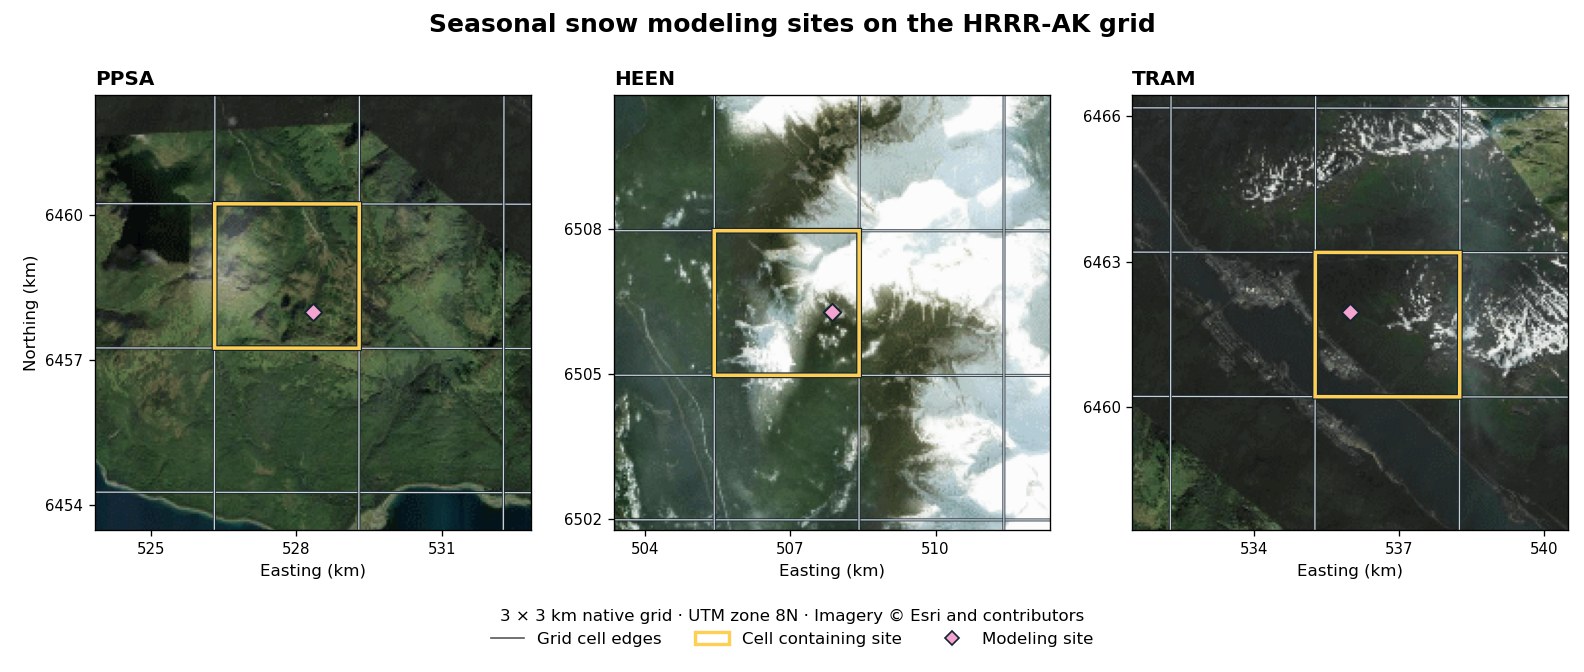

In [4]:
outline = '#ffcf53'
point = '#f4a4d0'
shadow = pe.withStroke(linewidth=1.8, foreground='#14232e', alpha=.87)
site_order = ('PPSA', 'TRAM', 'HEEN')


def draw_map(ax, site, bounds=None, *, grid=None):
    ax.imshow(site['image'], extent=np.array(site['image_extent']) / 1000, origin='upper')
    if grid is None:
        for x, y in [(grid_x, grid_y), (grid_x.T, grid_y.T)]:
            ax.plot(x.T / 1000, y.T / 1000, color='white', alpha=.8, lw=.75,
                    path_effects=[shadow], zorder=2)
        cell = site['cell']
    else:
        segments, cell = grid
        ax.add_collection(LineCollection(segments / 1000, colors='white', alpha=.8,
                                         linewidths=.6, path_effects=[shadow], zorder=2))
    ax.add_patch(Polygon(cell / 1000, closed=True, fill=False,
                         edgecolor=outline, linewidth=2.1, zorder=3,
                         path_effects=[pe.withStroke(linewidth=3.5, foreground='#14232e')]))
    ax.scatter(site['x'] / 1000, site['y'] / 1000, marker='D', s=55, color=point,
               edgecolor='#14232e', linewidth=1.2, zorder=4)
    west, south, east, north = np.array(site['extent'] if bounds is None else bounds) / 1000
    ax.set(xlim=(west, east), ylim=(south, north), aspect='equal')
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(MaxNLocator(nbins=4, integer=True))
    ax.ticklabel_format(useOffset=False, style='plain')
    ax.tick_params(labelsize=9)


def map_legend(fig, *, native_only=True):
    handles = [
        Line2D([], [], color='.35', lw=1, label='Grid cell edges'),
        Patch(fill=False, edgecolor=outline, linewidth=2,
              label='Cell containing site' if native_only else 'Highlighted site cell'),
        Line2D([], [], color=point, marker='D', markeredgecolor='#14232e', linestyle='none',
               label='Modeling site'),
    ]
    attribution = 'UTM zone 8N · Imagery © Esri and contributors'
    if native_only:
        attribution = f'{dx / 1000:g} × {dy / 1000:g} km native grid · {attribution}'
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .015),
               ncols=3, frameon=False, title=attribution)

fig, axes = plt.subplots(1, 3, figsize=(13.2, 5.6))
fig.subplots_adjust(left=.06, right=.99, bottom=.19, top=.88, wspace=.19)
fig.suptitle('Seasonal snow modeling sites on the HRRR-AK grid',
             weight='bold', fontsize=15, y=.98)
for ax, (name, site) in zip(axes, sites.items()):
    draw_map(ax, site)
    ax.set_title(name, loc='left', weight='bold')
    ax.set_xlabel('Easting (km)')
axes[0].set_ylabel('Northing (km)')
map_legend(fig)
plt.show()

## HEEN close-up

A larger map covers 6 × 6 km around HEEN, including the full native cell containing the modeling point.

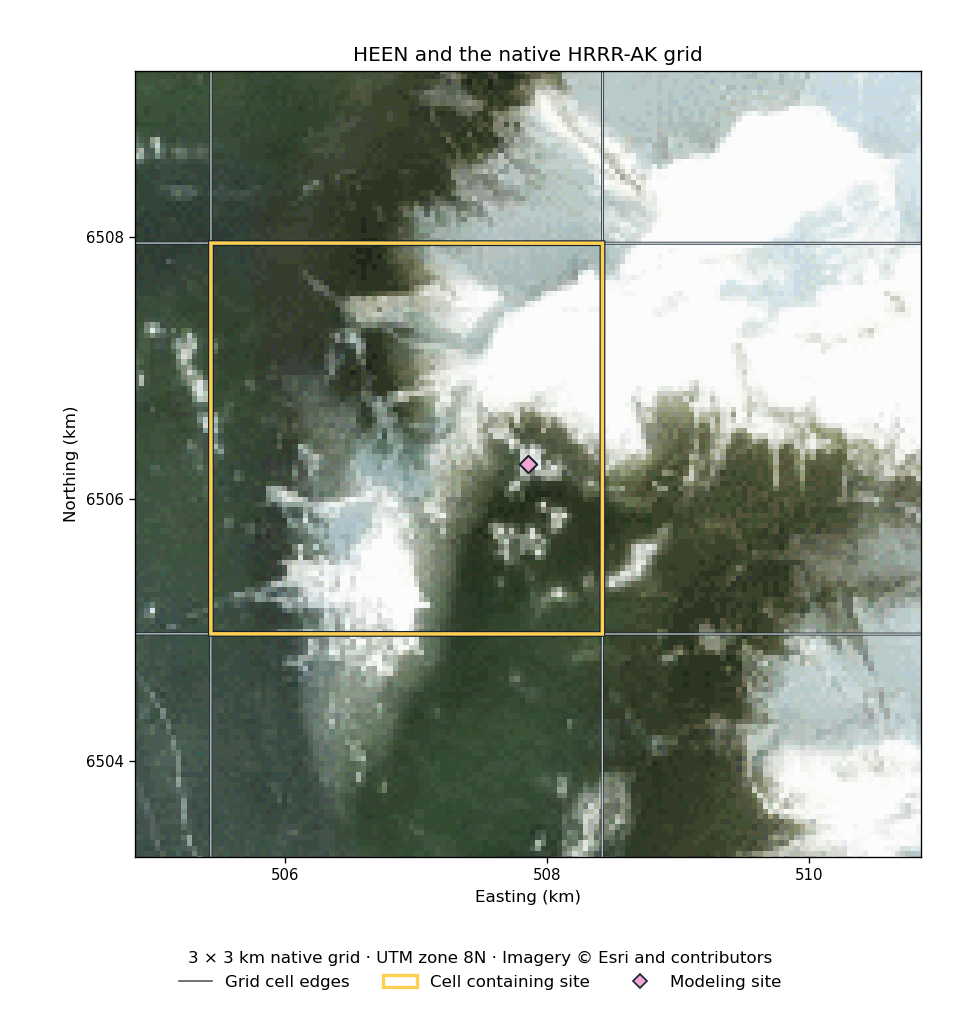

In [5]:
heen = sites['HEEN']
x, y = heen['x'], heen['y']
heen_bounds = (x - 3000, y - 3000, x + 3000, y + 3000)

fig, ax = plt.subplots(figsize=(8, 8.5))
fig.subplots_adjust(left=.12, right=.98, bottom=.16, top=.93)
draw_map(ax, heen, heen_bounds)
ax.set(title='HEEN and the native HRRR-AK grid',
       xlabel='Easting (km)', ylabel='Northing (km)')
map_legend(fig)
plt.show()

## Native grid maps stacked vertically

PPSA, TRAM, and HEEN use the same 9 × 9 km extents as the horizontal overview.

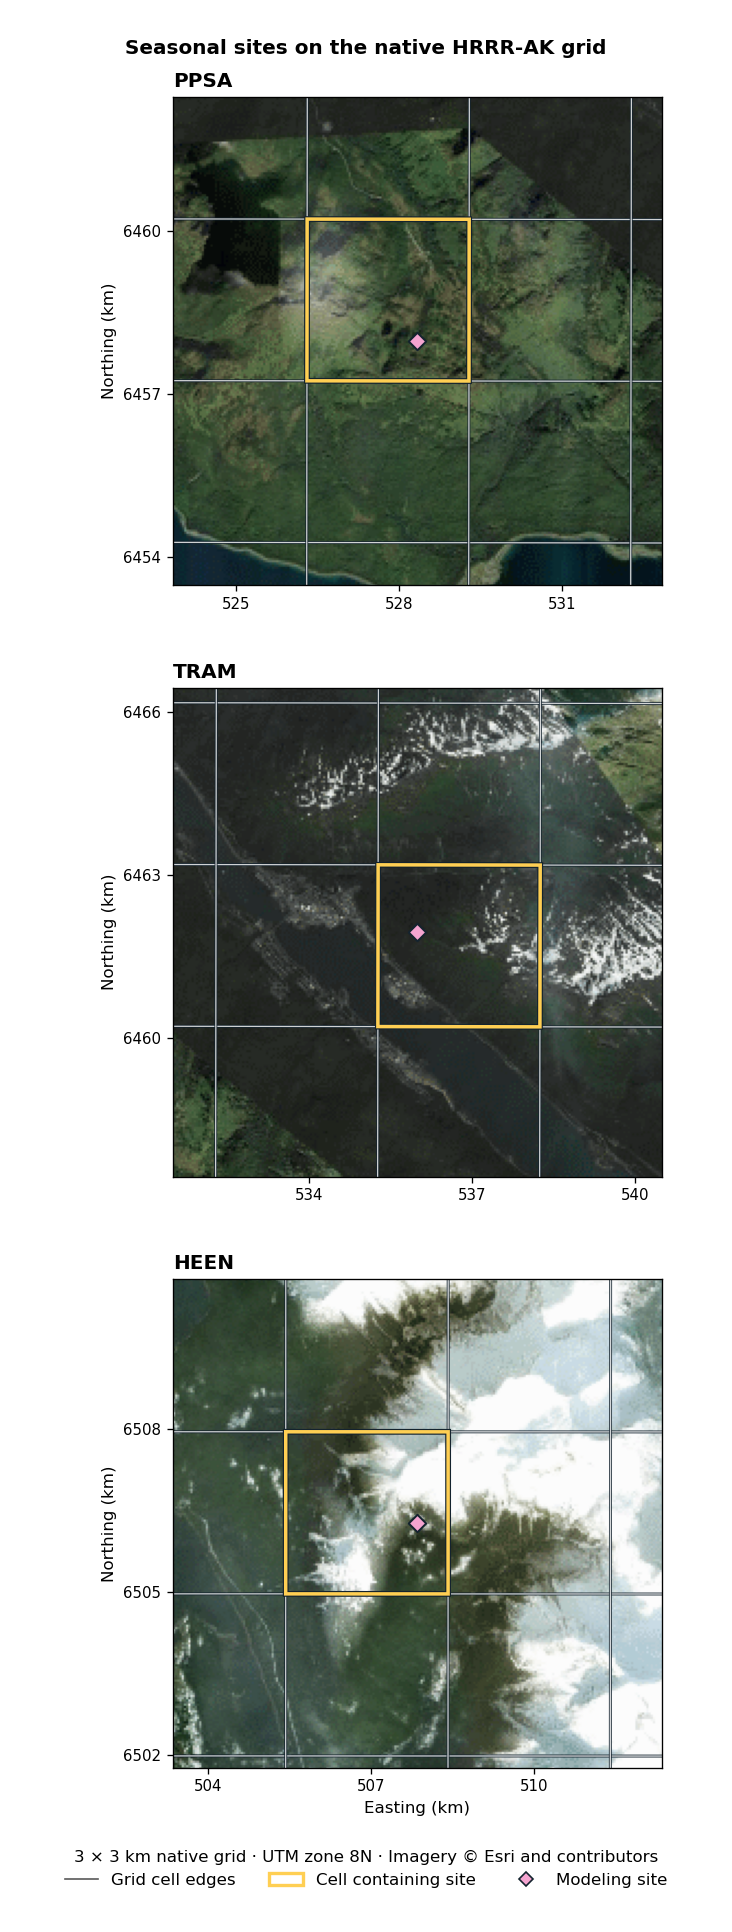

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(6.1, 16.1))
fig.subplots_adjust(left=.16, right=.98, bottom=.085, top=.95, hspace=.21)
fig.suptitle('Seasonal sites on the native HRRR-AK grid', weight='bold', y=.98)
for ax, name in zip(axes, site_order):
    draw_map(ax, sites[name])
    ax.set_title(name, loc='left', weight='bold')
    ax.set_ylabel('Northing (km)')
axes[-1].set_xlabel('Easting (km)')
map_legend(fig)
plt.show()

## WY2021 downscaling grids

Each row uses the same imagery and 9 × 9 km extent across the native HRRR-AK, 1,000 m, and 500 m panels. The downscaled grids come from the WY2021 TopoPyScale terrain files. Grid lines bound cells with valid forcing. The gold outline marks the cell containing the site in the native panels and the archived forcing cell in the downscaled panels. The notebook checks each archived cell ID against the terrain grid and the selection rule in the seasonal run script.

Set TOPOPYSCALE_WY2021_ROOT and SEASONAL_MODEL_ROOT to override the local terrain and archived simulation directories.

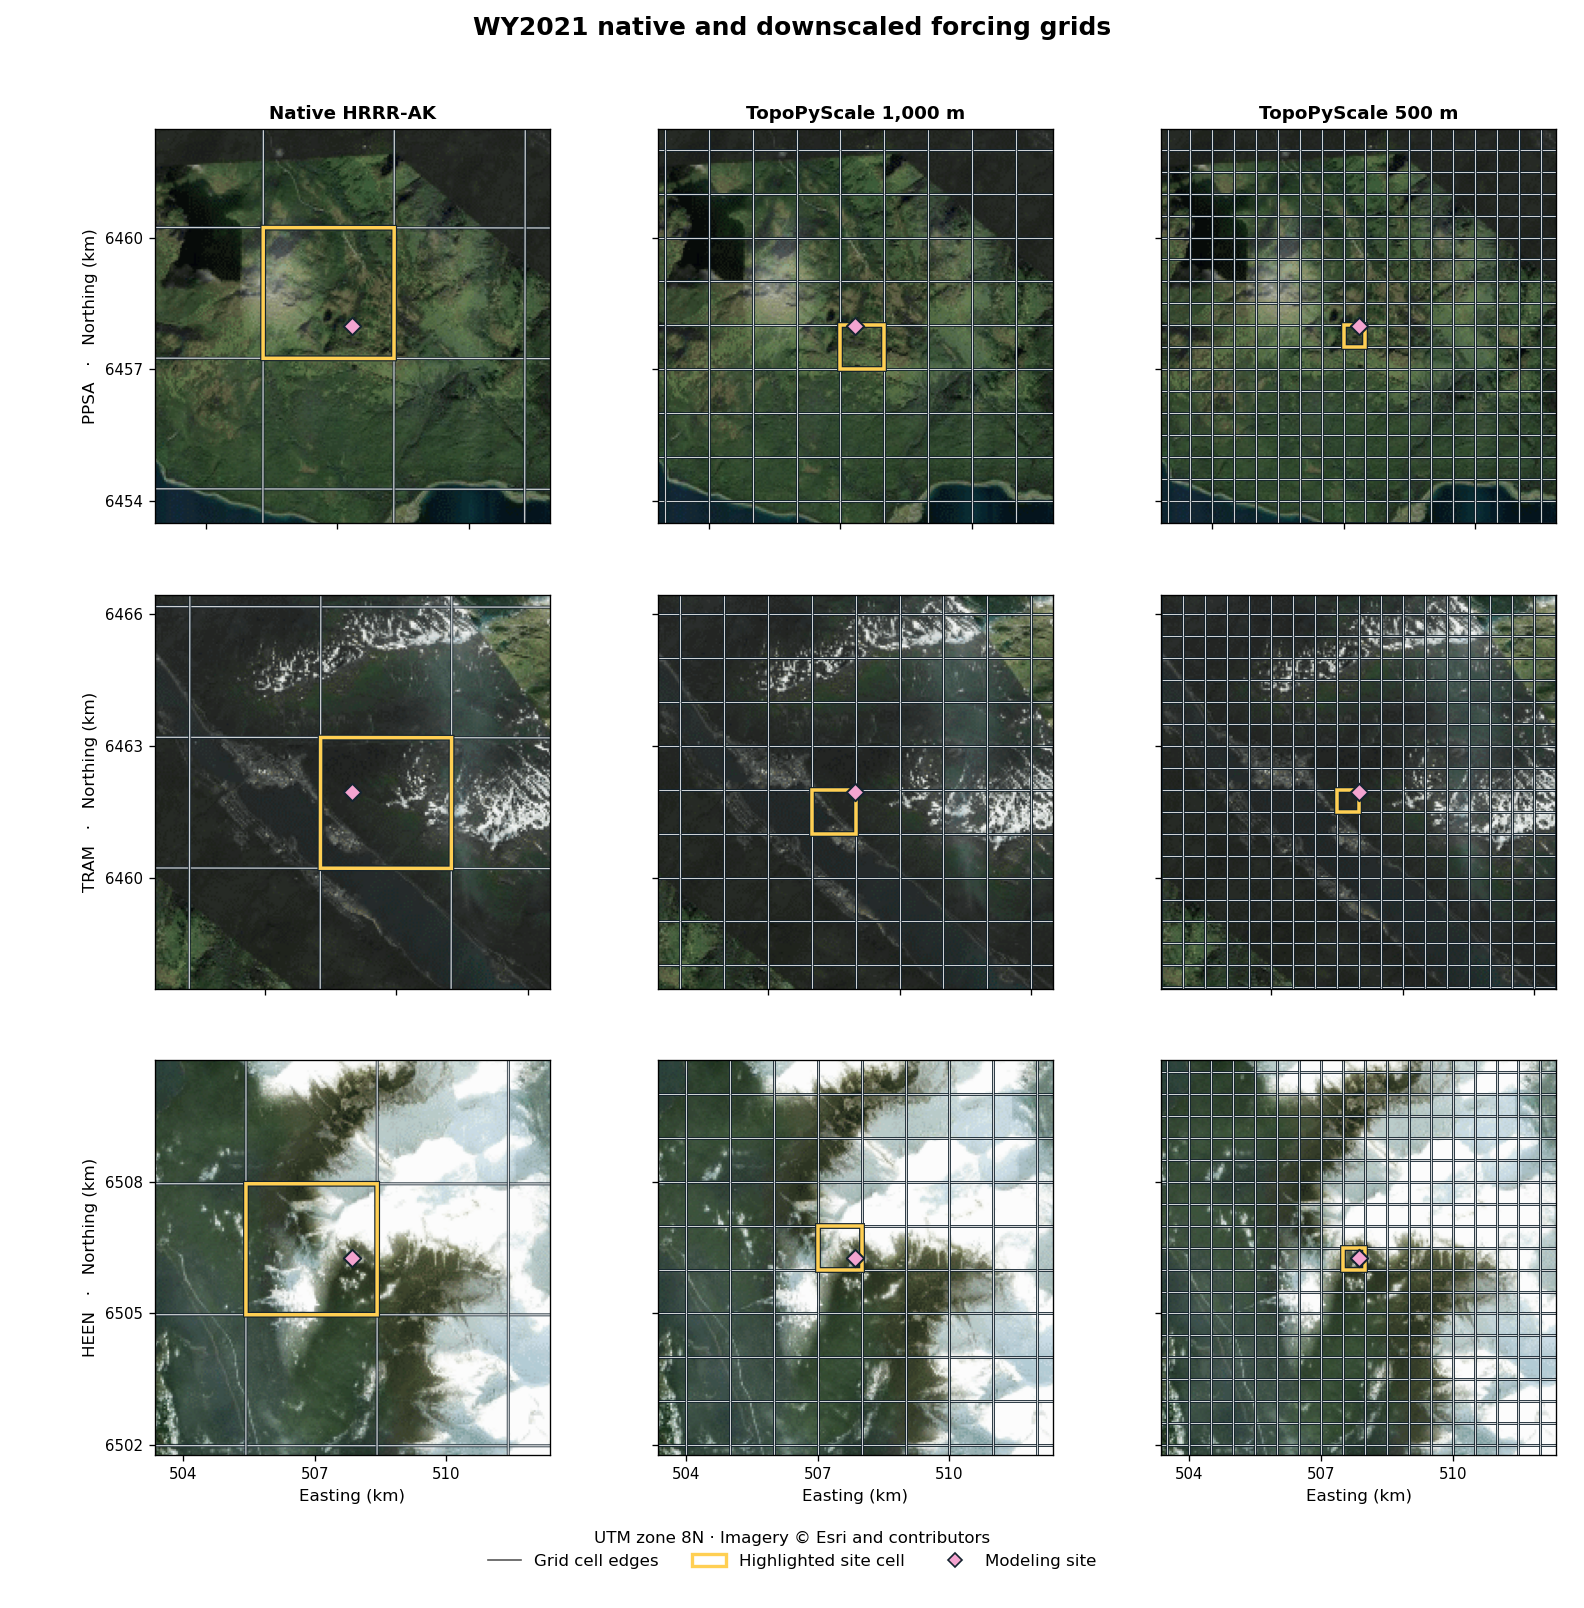

In [7]:
import sys
import xarray as xr

sys.path.insert(0, str(root / 'modeling/downscaling'))
from run_seasonal_topopyscale import GRID, MODEL, RESOLUTIONS

terrain_root = Path(os.environ.get('TOPOPYSCALE_WY2021_ROOT', GRID)).expanduser()
model_root = Path(os.environ.get('SEASONAL_MODEL_ROOT', MODEL)).expanduser()


def valid_cell_edges(x, y, valid, resolution):
    # An edge is present if at least one of its neighboring cells has forcing.
    horizontal = np.pad(valid, ((1, 0), (0, 0))) | np.pad(valid, ((0, 1), (0, 0)))
    vertical = np.pad(valid, ((0, 0), (1, 0))) | np.pad(valid, ((0, 0), (0, 1)))
    x_edges = np.r_[x - resolution / 2, x[-1] + resolution / 2]
    y_edges = np.r_[y + resolution / 2, y[-1] - resolution / 2]
    row, col = np.nonzero(horizontal)
    h_lower = np.column_stack((x_edges[col], y_edges[row]))
    h_upper = np.column_stack((x_edges[col + 1], y_edges[row]))
    row, col = np.nonzero(vertical)
    v_lower = np.column_stack((x_edges[col], y_edges[row]))
    v_upper = np.column_stack((x_edges[col], y_edges[row + 1]))
    return np.stack([np.vstack((h_lower, v_lower)), np.vstack((h_upper, v_upper))], axis=1)


def load_site_grids(resolution):
    path = terrain_root / f'{resolution}m' / 'terrain.nc'
    grids = {}
    with xr.open_dataset(path) as terrain:
        if terrain.attrs['crs'] != f'EPSG:{utm}' or terrain.attrs['resolution_m'] != resolution:
            raise ValueError(f'Unexpected grid CRS or spacing in {path}')
        ids = terrain.cell_id.transpose('y', 'x')
        np.testing.assert_allclose(np.diff(ids.x), resolution)
        np.testing.assert_allclose(np.diff(ids.y), -resolution)
        for name, site in sites.items():
            run = f'topopyscale_{resolution}m_{name.lower()}_WY2021'
            metadata = model_root / name.lower() / 'input' / f'topopyscale_{resolution}m_WY2021'
            cell_id = json.loads((metadata / f'{run}.json').read_text())['cell']
            chosen = ids.sel(x=site['x'], y=site['y'], method='nearest')
            x, y = float(chosen.x), float(chosen.y)
            half = resolution / 2
            if (cell_id < 0 or int(chosen) != cell_id
                    or abs(site['x'] - x) > half or abs(site['y'] - y) > half):
                raise ValueError(f'Archived forcing cell does not match terrain selection for {run}')
            west, south, east, north = site['extent']
            local = ids.sel(x=slice(west - half, east + half), y=slice(north + half, south - half))
            segments = valid_cell_edges(local.x.values, local.y.values, local.values >= 0, resolution)
            cell = np.array([(x - half, y - half), (x + half, y - half),
                             (x + half, y + half), (x - half, y + half)])
            grids[name] = segments, cell
    return grids


downscaled = {resolution: load_site_grids(resolution) for resolution in RESOLUTIONS}

def plot_grid_comparison(*, zoom_by_resolution=False):
    fig, axes = plt.subplots(3, 3, figsize=(13.2, 13.4))
    fig.subplots_adjust(left=.09, right=.99, bottom=.095, top=.92, hspace=.18, wspace=.20)
    title = ('WY2021 forcing grids at increasing zoom' if zoom_by_resolution
             else 'WY2021 native and downscaled forcing grids')
    fig.suptitle(title, weight='bold', fontsize=15, y=.99)
    columns = (None, *RESOLUTIONS)
    labels = ('Native HRRR-AK', 'TopoPyScale 1,000 m', 'TopoPyScale 500 m')
    widths = (2 * half_width, 3000, 1500)
    for col, (label, width) in enumerate(zip(labels, widths)):
        heading = f'{label} · {width / 1000:g} km across' if zoom_by_resolution else label
        axes[0, col].set_title(heading, weight='bold', fontsize=11)
    for row, name in enumerate(site_order):
        site = sites[name]
        for col, (resolution, width) in enumerate(zip(columns, widths)):
            ax = axes[row, col]
            grid = None if resolution is None else downscaled[resolution][name]
            bounds = None
            if zoom_by_resolution and grid is not None:
                x, y = grid[1].mean(axis=0)
                half = width / 2
                bounds = (x - half, y - half, x + half, y + half)
            draw_map(ax, site, bounds=bounds, grid=grid)
            ax.tick_params(labelbottom=row == len(site_order) - 1,
                           labelleft=zoom_by_resolution or col == 0)
            if row == len(site_order) - 1:
                ax.set_xlabel('Easting (km)')
        axes[row, 0].set_ylabel(f'{name}   ·   Northing (km)')
    map_legend(fig, native_only=False)
    plt.show()


plot_grid_comparison()

## WY2021 grids at increasing zoom

The native view spans 9 km. The 1,000 m and 500 m views are centered on the archived forcing cells and span 3 km and 1.5 km, respectively. This keeps the highlighted cell about the same size on the page while revealing its immediate surroundings.

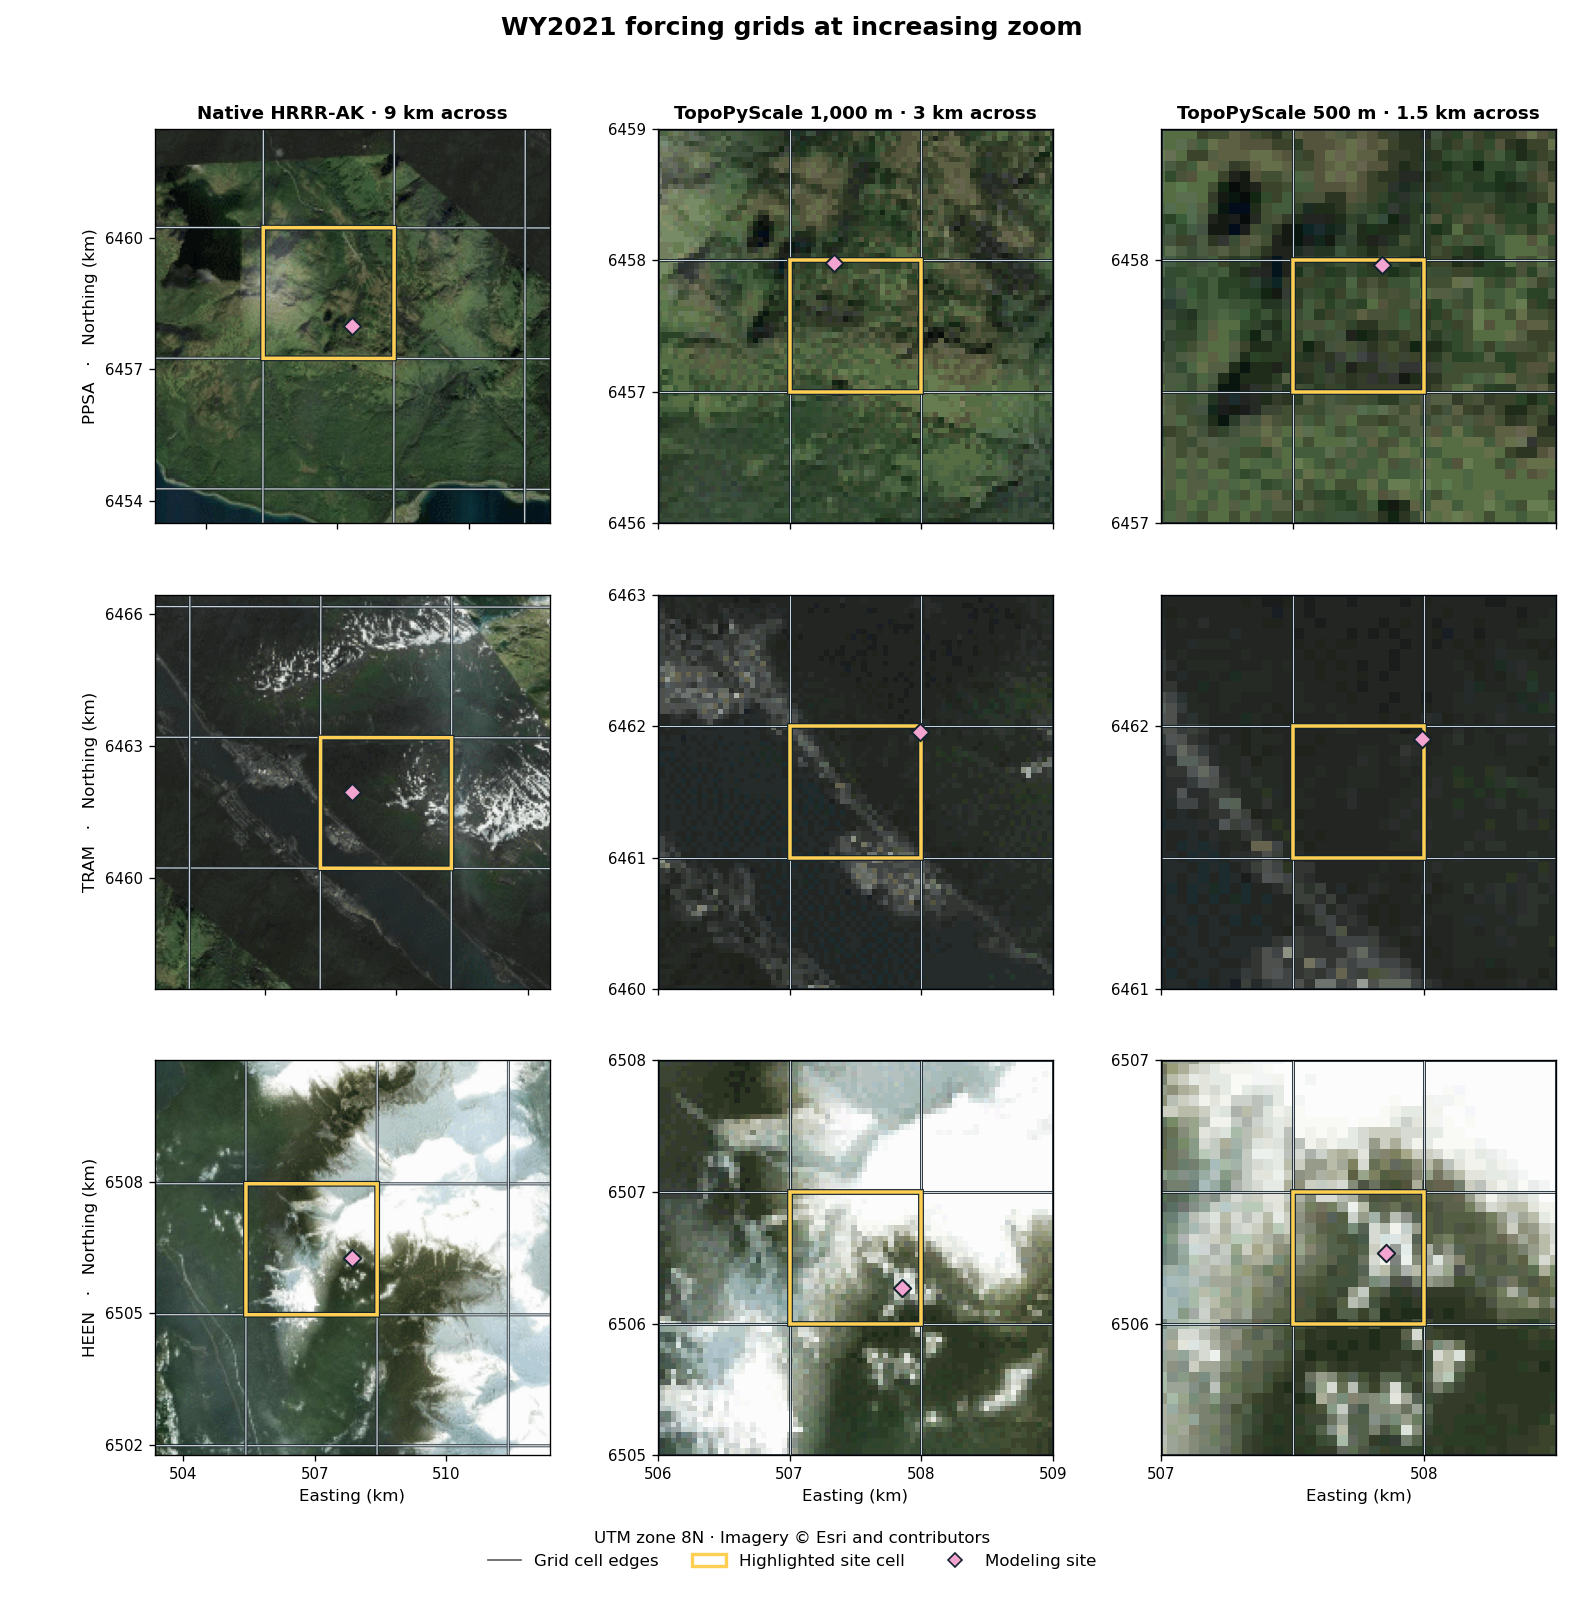

In [8]:
plot_grid_comparison(zoom_by_resolution=True)